In [1]:
!pip3.11 install pyspark==3.5.0
!pip3.11 install findspark
!pip3.11 install matplotlib
!pip3.11 install pandas


[notice] A new release of pip available: 22.3.1 -> 24.0
[notice] To update, run: python3.11 -m pip install --upgrade pip

[notice] A new release of pip available: 22.3.1 -> 24.0
[notice] To update, run: python3.11 -m pip install --upgrade pip

[notice] A new release of pip available: 22.3.1 -> 24.0
[notice] To update, run: python3.11 -m pip install --upgrade pip

[notice] A new release of pip available: 22.3.1 -> 24.0
[notice] To update, run: python3.11 -m pip install --upgrade pip


In [38]:
from pyspark.sql import SparkSession
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
# Initialize Spark session
spark = SparkSession.builder \
    .appName("PostgreSQL Connection") \
    .config("spark.driver.extraClassPath", "/Users/david/Downloads/postgresql-42.7.2.jar") \
    .getOrCreate()

# Define PostgreSQL connection properties
postgresql_url = "jdbc:postgresql://127.0.0.1:5432/postgres"
postgresql_properties = {
    "user": "you",
    "password": "you.com",
    "driver": "org.postgresql.Driver"
}

# Read data from PostgreSQL table into a Spark DataFrame
df = spark.read \
    .jdbc(url=postgresql_url, table="tz_table", properties=postgresql_properties)

# Perform operations on the DataFrame as needed
df.show()



+--------------------+--------------------+-----+------------+--------+
|            referrer|               title|count|date_created|    type|
+--------------------+--------------------+-----+------------+--------+
|        other-search|Henryk_Kossowski_...|   11|  2024-02-26|external|
|        other-search|     Löbtauer_Brücke|   15|  2024-02-26|external|
|        other-search|  Anne-Sophie_Brasme|   31|  2024-02-26|external|
|          Der_Fremde|  Anne-Sophie_Brasme|   17|  2024-02-26|    link|
|        other-search|Markus_Witte_(Unt...|   73|  2024-02-26|external|
|              Babbel|Markus_Witte_(Unt...|   51|  2024-02-26|    link|
|         other-empty|Markus_Witte_(Unt...|   16|  2024-02-26|external|
|          Megingiard|          Jarngreipr|   37|  2024-02-26|    link|
|        other-search|          Jarngreipr|   55|  2024-02-26|external|
|SWEG_Südwestdeuts...|     Zollernalbkreis|   10|  2024-02-26|    link|
|Liste_der_Landkre...|     Zollernalbkreis|   10|  2024-02-26|  

In [39]:
pandas_df = df.toPandas()
pandas_df=pandas_df.drop_duplicates(["referrer","title","count","type"])
pandas_df[pandas_df["title"].isna()]
pandas_df[pandas_df["referrer"].isna()]
pandas_df[pandas_df["type"].isna()]
#No empty column

,referrer,title,count,date_created,type


/var/folders/kj/1l2j6gv51hd6ybvv8ztml9wm0000gn/T/ipykernel_16252/1652489146.py:26: MatplotlibDeprecationWarning: The legendHandles attribute was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use legend_handles instead.
  for each in plt.gca().legend().legendHandles:


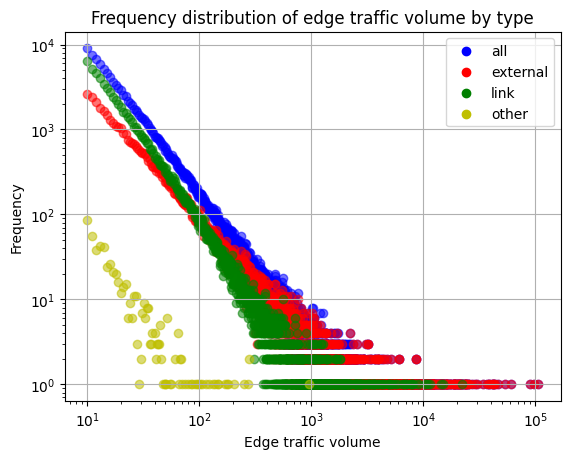

In [68]:
external_edges = pandas_df[pandas_df.type == 'external']
link_edges = pandas_df[pandas_df.type == 'link']
other_edges = pandas_df[pandas_df.type == 'other']
edge_traffic_frequencies = pandas_df['count'].value_counts()
external_edges_traffic_frequencies = external_edges['count'].value_counts()
link_edges_traffic_frequencies = link_edges['count'].value_counts()
other_edges_traffic_frequencies = other_edges['count'].value_counts()

my_alpha = 0.55
plt.scatter(edge_traffic_frequencies.index.values, edge_traffic_frequencies.values, \
            c="b", label="all", alpha=my_alpha)
plt.scatter(external_edges_traffic_frequencies.index.values, external_edges_traffic_frequencies.values, \
            c="r", label="external", alpha=my_alpha)
plt.scatter(link_edges_traffic_frequencies.index.values, link_edges_traffic_frequencies.values, \
            c="g", label="link", alpha=my_alpha)
plt.scatter(other_edges_traffic_frequencies.index.values, other_edges_traffic_frequencies.values, \
            c="y", label="other", alpha=my_alpha)
plt.xscale("log")
plt.yscale("log")
plt.xlabel('Edge traffic volume')
plt.ylabel('Frequency')
plt.grid(True)
plt.legend()

# make the legend markers opaque
for each in plt.gca().legend().legendHandles:
    each.set_alpha(1)


plt.title("Frequency distribution of edge traffic volume by type");

In [67]:
print('''
 The above diagram shows that the majority of edges with extremely high traffic volume have external referers. It also shows that the external reference type distribution has a different slope from the other two.
''')


 The above diagram shows that the majority of edges with extremely high traffic volume have external referers. It also shows that the external reference type distribution has a different slope from the other two.



In [64]:
print('''
other-external: External website referers, indicating that the user navigated from an external website to a Wikipedia article page.
other-search: External search referers, which occur when a person searches for something on a search engine website and then navigates to a Wikipedia article page.
Other-internal: Referrals to other Wikimedia projects. It might be a separate language Wikipedia, or another Wikimedia project that is not a Wikipedia.
other-empty is an empty referer. This might be the consequence of a browser homepage setting, a security feature, a bot, and so on.
Other-other: Any other remote referrer.
''')


other-external: External website referers, indicating that the user navigated from an external website to a Wikipedia article page.
other-search: External search referers, which occur when a person searches for something on a search engine website and then navigates to a Wikipedia article page.
Other-internal: Referrals to other Wikimedia projects. It might be a separate language Wikipedia, or another Wikimedia project that is not a Wikipedia.
other-empty is an empty referer. This might be the consequence of a browser homepage setting, a security feature, a bot, and so on.
Other-other: Any other remote referrer.



In [41]:
pandas_df_sorted = pandas_df.sort_values("count", ascending=False)
pandas_df_sorted.head(20)

,referrer,title,count,date_created,type
40392,other-other,ZDF,105932,2024-02-26,external
89521,other-search,Elisabeth_von_Österreich-Ungarn,96941,2024-02-26,external
33176,other-empty,ZDF,89240,2024-02-26,external
92538,other-search,Alica_Schmidt,61258,2024-02-26,external
29723,other-empty,Dead_for_a_Dollar,54031,2024-02-26,external
122442,other-search,Dünentod_–_Ein_Nordsee-Krimi,46532,2024-02-27,external
22098,other-search,Liste_der_Großstädte_in_Deutschland,43279,2024-02-26,external
59044,other-search,Phantastische_Tierwesen_(Filmreihe),42578,2024-02-26,external
60928,other-search,Lucas_Gregorowicz,41902,2024-02-26,external
23879,other-search,Vierschanzentournee_2023/24,41857,2024-02-26,external


In [59]:
print('''The edges with the biggest visitation volume are primarily located outside of the English Wikipedia. The edge with the most traffic has a search referer. 
Similarly, additional major sources of visitor volume include external searches, other Wikipedias, and more other websites.''')

The edges with the biggest visitation volume are primarily located outside of the English Wikipedia. The edge with the most traffic has a search referer. 
Similarly, additional major sources of visitor volume include external searches, other Wikipedias, and more other websites.


In [42]:
#spliting out the type=external referers as a different kind of data, supplemental to the article-to-article network
pd.options.display.float_format = '{:.4f}'.format
edges_count = pandas_df_sorted.groupby("type")['count'].count()
edges_count.rename("edges_count", inplace=True)
traffic_volume = pandas_df_sorted.groupby("type")['count'].sum()
traffic_volume.rename("traffic_volume", inplace=True)
summarize_by_type = pd.concat([edges_count, traffic_volume], axis=1)
summarize_by_type["edges_count_pct"] = summarize_by_type["edges_count"] / summarize_by_type["edges_count"].sum()
summarize_by_type["traffic_volume_pct"] = summarize_by_type["traffic_volume"] / summarize_by_type["traffic_volume"].sum()
summarize_by_type

,edges_count,traffic_volume,edges_count_pct,traffic_volume_pct
type,,,,
external,52217,11438463,0.4052,0.7242
link,76065,4340391,0.5903,0.2748
other,578,15354,0.0045,0.0010


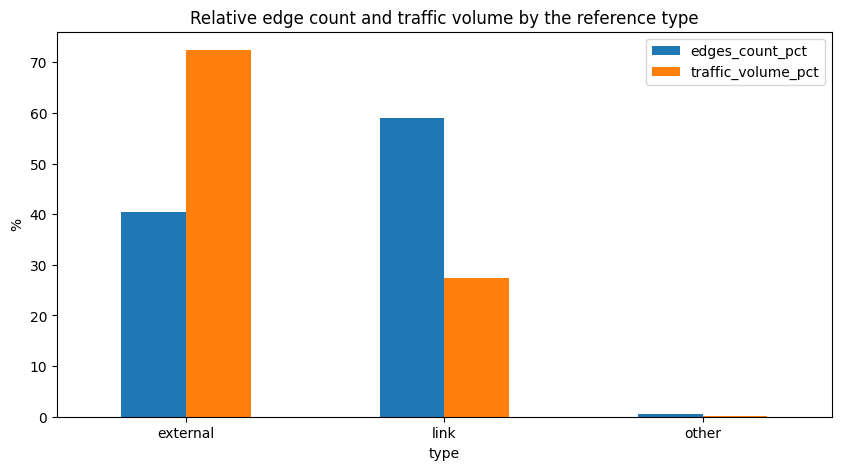

In [34]:
ax = plt.gca()
(summarize_by_type[["edges_count_pct", "traffic_volume_pct"]]*100).plot(kind = "bar", ax=ax)
plt.xticks(np.arange(len(summarize_by_type.index)), summarize_by_type.index, rotation=0)
ax.set_title("Relative edge count and traffic volume by the reference type")
ax.set_ylabel("%")

# adjust this fig size
fig = plt.gcf()
fig.set_size_inches(10,5);

In [55]:
print('An external reference type accounts for approximately 72% of traffic flow. Article-to-article links account for 27% of visitor flow, with the remaining 0.1% coming from "other" references. Internal searching from a Wikipedia article page falls under the category of "other" references.')

An external reference type accounts for approximately 72% of traffic flow. Article-to-article links account for 27% of visitor flow, with the remaining 0.1% coming from "other" references. Internal searching from a Wikipedia article page falls under the category of "other" references.


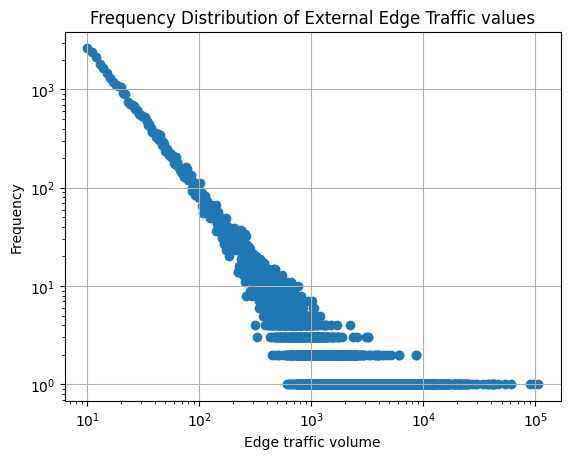

In [51]:
#lets dig more into type=external
external_edges = pandas_df_sorted[pandas_df_sorted.type == 'external']
external_edges_freq = external_edges['count'].value_counts()
plt.scatter(external_edges_freq.index.values, external_edges_freq.values)
plt.xscale("log")
plt.yscale("log")
plt.xlabel('Edge traffic volume')
plt.ylabel('Frequency')
plt.grid(True)
plt.title("Frequency Distribution of External Edge Traffic values");


In [48]:
edges_count = external_edges.groupby("referrer")['count'].count()
edges_count.rename("edges_count", inplace=True)
traffic_volume = external_edges.groupby("referrer")['count'].sum()
traffic_volume.rename("traffic_volume", inplace=True)
summary_by_prev = pd.concat([edges_count, traffic_volume], axis=1)

summary_by_prev["edges_count_pct"] = summary_by_prev["edges_count"] / summary_by_prev["edges_count"].sum()
summary_by_prev["traffic_volume_pct"] = summary_by_prev["traffic_volume"] / summary_by_prev["traffic_volume"].sum()

summary_by_prev

,edges_count,traffic_volume,edges_count_pct,traffic_volume_pct
referrer,,,,
other-empty,16752,2152089,0.3208,0.1881
other-external,2852,124513,0.0546,0.0109
other-internal,5692,260154,0.1090,0.0227
other-other,195,117873,0.0037,0.0103
other-search,26726,8783834,0.5118,0.7679


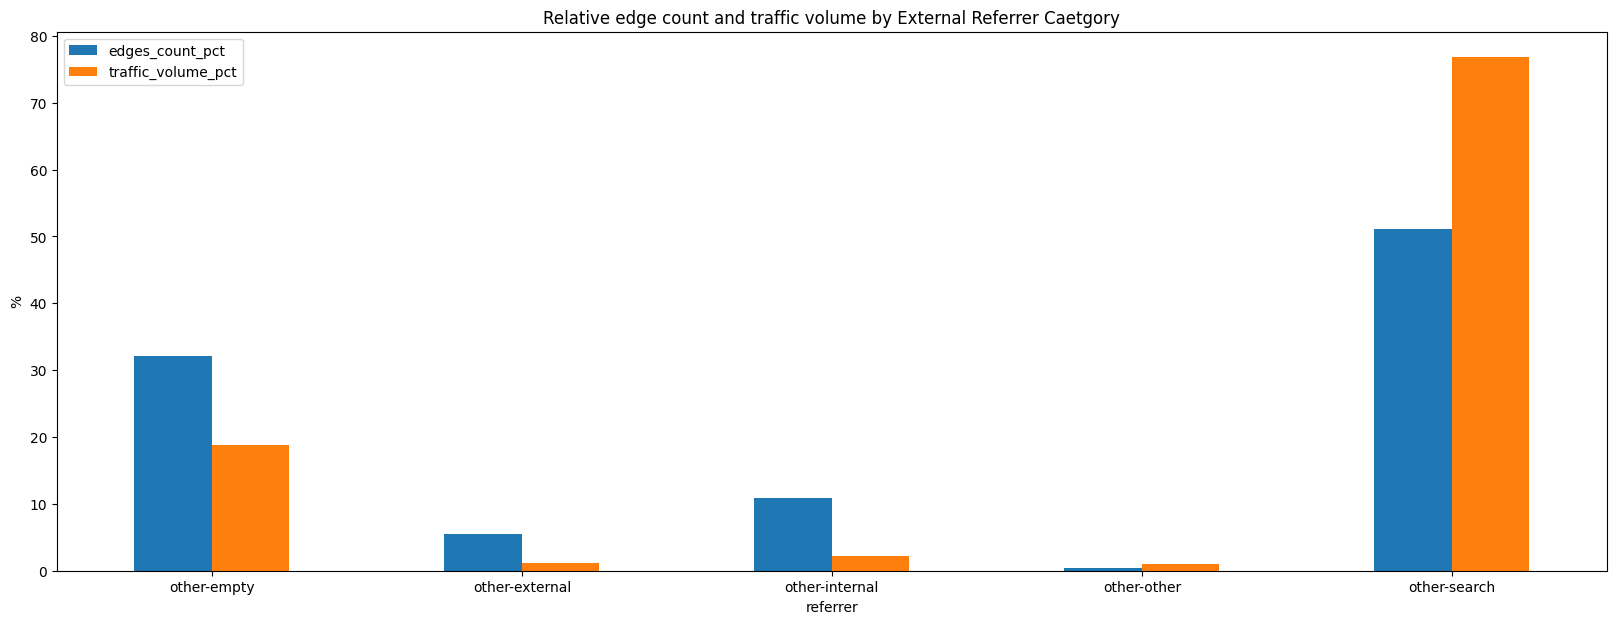

In [52]:
ax = plt.gca()
(summary_by_prev[["edges_count_pct", "traffic_volume_pct"]]*100).plot(kind = "bar", ax=ax)
plt.xticks(np.arange(len(summary_by_prev.index)), summary_by_prev.index, rotation=0)
ax.set_title("Relative edge count and traffic volume by External Referrer Caetgory")
ax.set_ylabel("%")
fig = plt.gcf()
fig.set_size_inches(20,7);

In [60]:
print('76.7% of external traffic comes from external searches, 18.8% has an empty referer, and the remaining external reference categories account for just 4.5% of traffic volume.')

76.7% of external traffic comes from external searches, 18.8% has an empty referer, and the remaining external reference categories account for just 4.5% of traffic volume.


Text(0.5, 1.0, 'Frequency Distribution of External Search Edge Traffic')

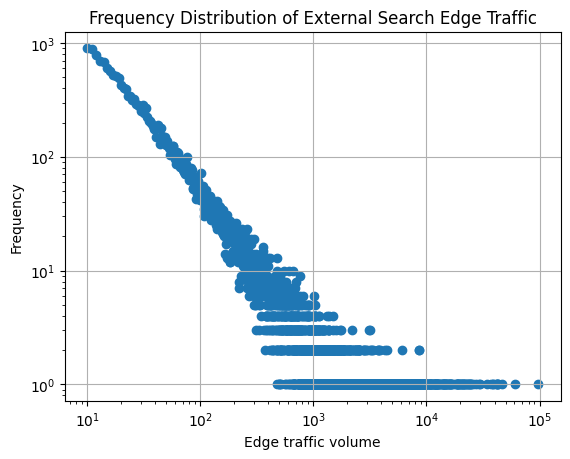

In [63]:
#lets explore external search referer category
external_search_edges = external_edges[external_edges.referrer == "other-search"]
external_search_edges_frequency = external_search_edges['count'].value_counts()
plt.scatter(external_search_edges_frequency.index.values, external_search_edges_frequency.values)
plt.xscale("log")
plt.yscale("log")
plt.xlabel('Edge traffic volume')
plt.ylabel('Frequency')
plt.grid(True)

plt.title("Frequency Distribution of External Search Edge Traffic")